# Visualize Rates
### Import libraries

In [1]:
import os
import sys
import importlib
import numpy as np
import pandas as pd

from tqdm.notebook import tqdm



Global paths

In [2]:
# Current Working Directory
CWD = os.getcwd()
# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']

In [3]:
# PyCOMET
PyCOMET = WORKSPACE + '/ML/PyCOMET/pycomet/'
if importlib.util.find_spec('pycomet') is None:
    sys.path.append(os.path.abspath(PyCOMET))

In [4]:
# SurQCT
SurQCT = WORKSPACE + '/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))

from surqct.src.chemical_systems import systems as syst
from surqct import config as cfg
from surqct.src.utilities import const

In [5]:
from tqdm import tqdm
from surqct import config as cfg
from surqct.src.utilities import utils
from surqct.src.utilities import const
from surqct.src.utilities import reading
from silx.io.dictdump import dicttoh5
from pycomet.math.welford import Welford

# Visualization libraries
matplotlib = utils.import_matplotlib()
from matplotlib import pyplot as plt
from matplotlib import ticker
# %matplotlib qt

Case-specific paths

In [6]:
# Output directory
out_dir = CWD + './Output/VisualizeRates/'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

In [7]:
SystemName   = 'O3_UMN'
SuffixHDF5 = {
    'QCT':    '/Orig/',
    'SurQCT': '/diss/configs.ln/config.01/run.01/'
}
TTranVec    = [1500, 2500, 5000, 8000, 10000, 12000, 15000, 20000]
RatesType   = ['Diss']

In [8]:
Systems = {}
RatesTypes = {}
for Identifier in SuffixHDF5.keys():
    KinSource = Identifier.split('-')[0]
    Systems[Identifier] = syst.get_system(
        NameLong=SystemName,
        KinSource=KinSource,
        ProcNames=RatesType,
        PathToHDF5Fld=cfg.paths.HDF5Dtb + '/' + KinSource + '/' + SuffixHDF5[Identifier]
    )
    # Reading rates
    Systems[Identifier].Processes.read_rates(TTranVec=TTranVec)

In [9]:
def plot_prediction2D(
    System,
    Path,
    TrueData,
    PredData,
    XAxis='EInt'
):
    MolIn  = System.Processes.CompInOut['Diss']['In'][0]
    
    # Rates and j-th level data
    iIdxTrue, KTrue = TrueData
    iIdxPred, KPred = PredData
    XTrue = MolIn.DiatData[XAxis].to_numpy()[iIdxTrue]
    XPred = MolIn.DiatData[XAxis].to_numpy()[iIdxPred]
    
    XLbl = const.diat_data_lbl[XAxis]

    # Figure
    fig = plt.figure()
    plt.scatter(XTrue, KTrue, c='k', s=3, label='QCT')
    plt.scatter(XPred, KPred, c='r', s=3, label='SurQCT')
    plt.yscale('log')
    plt.legend()
    plt.xlabel(XLbl)
    plt.ylabel(r'$k_{i}$ [$cm^3$/s]')

    plt.show()

    # plt.savefig(Path + f'/diss.pdf')

    return fig

In [10]:
def plot_prediction3D(
    System,
    Path,
    TrueData,
    PredData,
    XYAxis=['ECB', 'rOut']
):
    MolIn  = System.Processes.CompInOut['Diss']['In'][0]
    
    
    Systems[Identifier].Processes.read_rates(TTranVec=TTranVec)
    MolIn  = System.Processes.CompInOut['Diss']['In'][0]
    
    # Rates and j-th level data
    iIdxTrue, KTrue = TrueData
    iIdxPred, KPred = PredData
    XYTrue = MolIn.DiatData[XYAxis].to_numpy()[iIdxTrue]
    XYPred = MolIn.DiatData[XYAxis].to_numpy()[iIdxPred]
    
    MolIn.LevelsData.iloc[kIdxVec]
    
    XYLbl = [const.diat_data_lbl[k] for k in XYAxis]
    
    # Figure
    fig = plt.figure(figsize=np.array([6.4,4.8])*1.5)
    ax = fig.add_subplot(projection='3d')
    ax.set_xlabel(XYLbl[0])
    ax.set_ylabel(XYLbl[1])
    ax.set_zlabel(r'$k_{i}$ [$cm^3$/s]')

    ax.view_init(elev=25., azim=-45)
    ax.dist = 9.5

    ax.zaxis.set_major_formatter(ticker.FuncFormatter(utils.log_tick_formatter))
    ax.zaxis.set_major_locator(ticker.MaxNLocator(integer=True))

    ax.scatter(np.log(XYTrue[:,0]), np.log(XYTrue[:,1]), np.log10(KTrue+1.e-16), c='k', s=3, label='QCT')
    ax.scatter(np.log(XYPred[:,0]), np.log(XYPred[:,1]), np.log10(KPred+1.e-16), c='r', s=3, label='SurQCT')

    plt.tight_layout()

    plt.show()

    # plt.savefig(Path + f'/diss.pdf')

    # return fig

1500


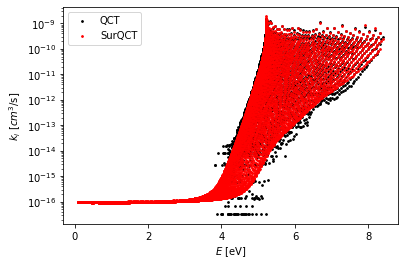

2500


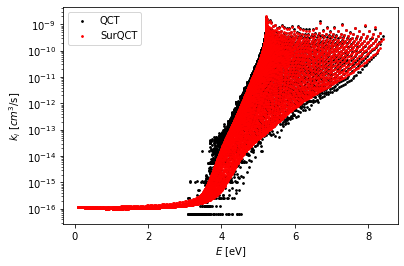

5000


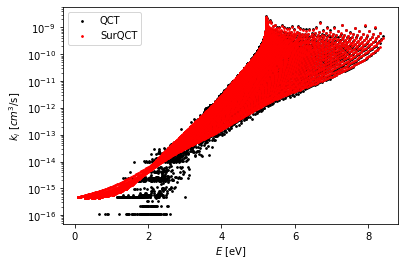

8000


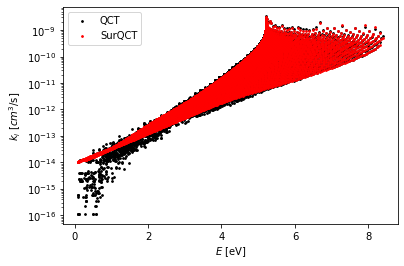

10000


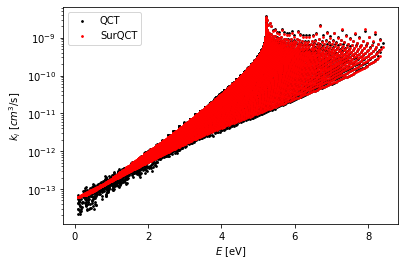

12000


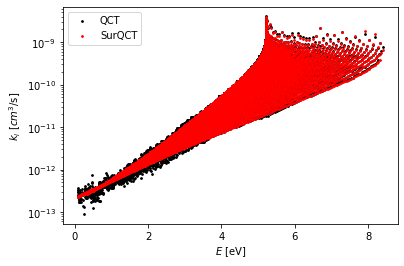

15000


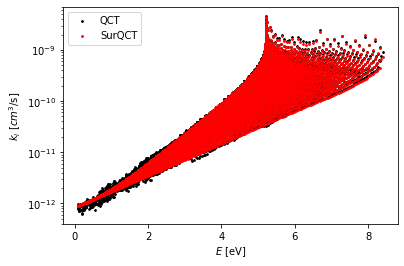

20000


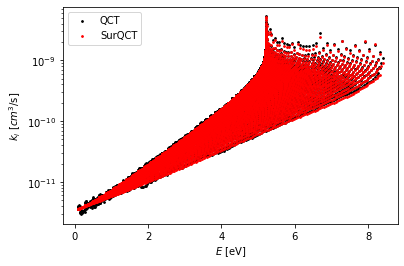

In [11]:
for T in TTranVec:
    NLevels  = Systems['QCT'].Processes.CompInOut['Diss']['In'][0].NLevels
    TrueData = (np.arange(NLevels), Systems['QCT'].Processes.Rates['Diss'][str(int(T))])
    PredData = (np.arange(NLevels), Systems['SurQCT'].Processes.Rates['Diss'][str(int(T))])
    print(T)
    plot_prediction2D(Systems['QCT'], './', TrueData, PredData)